# Cat-Dog Image Classifier

### Importing Libraries

In [1]:
import os, tensorflow as tf
print(os.environ.get('LD_LIBRARY_PATH')[:80])
print(tf.config.list_physical_devices('GPU'))

I0000 00:00:1794677804.850933    1707 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794677805.500402    1707 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794677807.478022    1707 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


/home/harsh/Work/.venv-tf/lib/python3.11/site-packages/nvidia/curand/lib:/home/h
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
import tensorflow as tf
print(tf.config.list_physical_devices('GPU'))
from tensorflow.keras.utils import image_dataset_from_directory  # pyright: ignore
from tensorflow.keras import layers, Sequential # pyright: ignore
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint # pyright: ignore
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### Loading Images

In [3]:
train = image_dataset_from_directory(
    '../Data/catdog/training_set',
    validation_split = 0.2,
    subset = 'training',
    seed = 123,
    image_size = (180, 180),
    batch_size = 32
)

validation = image_dataset_from_directory(
    '../Data/catdog/training_set',
    validation_split = 0.2,
    subset = 'validation',
    seed = 123,
    image_size = (180, 180),
    batch_size = 32
)


test = image_dataset_from_directory(
    '../Data/catdog/test_set',
    seed = 123,
    image_size = (180, 180),
    batch_size = 32,
    shuffle = False
)

Found 8000 files belonging to 2 classes.
Using 6400 files for training.


I0000 00:00:1794677810.366390    1707 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9702 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060, pci bus id: 0000:01:00.0, compute capability: 8.6


Found 8000 files belonging to 2 classes.
Using 1600 files for validation.
Found 2000 files belonging to 2 classes.


### Scaling and augmenting 

In [4]:
augmenting = Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])
rescale = layers.Rescaling(1./255)

### Building The Model

In [5]:
model = Sequential([
    augmenting,
    rescale,
    layers.Conv2D(32,3, activation= 'relu', input_shape = (180,180,3)),
    layers.MaxPooling2D(),
    layers.Conv2D(64,3, activation= 'relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(128,3, activation= 'relu'),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation= 'relu'),
    layers.Dropout(0.4),
    layers.Dense(1, activation= 'sigmoid')
])

/home/harsh/Work/.venv-tf/lib/python3.11/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


### Compiling the model

In [6]:
model.compile(
    optimizer = 'adam',
    loss = 'binary_crossentropy',
    metrics = ['accuracy']
)

### Training the Model

In [7]:
early_stop = EarlyStopping(monitor= 'val_loss', patience= 5, restore_best_weights= True)
checkpoint = ModelCheckpoint('best_model.keras', monitor= 'val_accuracy', save_best_only= True)

history = model.fit(
    train,
    validation_data  = validation,
    epochs = 40,
    callbacks = [early_stop, checkpoint]
)

Epoch 1/40


/home/harsh/Work/.venv-tf/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1794677814.726556    1867 cuda_dnn.cc:461] Loaded cuDNN version 92801


200/200 ━━━━━━━━━━━━━━━━━━━━ 12s 35ms/step - accuracy: 0.5242 - loss: 0.7039 - val_accuracy: 0.5331 - val_loss: 0.6865
Epoch 2/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - accuracy: 0.5709 - loss: 0.6829 - val_accuracy: 0.5744 - val_loss: 0.6778
Epoch 3/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 7s 37ms/step - accuracy: 0.6167 - loss: 0.6588 - val_accuracy: 0.6481 - val_loss: 0.6301
Epoch 4/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 8s 41ms/step - accuracy: 0.6530 - loss: 0.6264 - val_accuracy: 0.6756 - val_loss: 0.6063
Epoch 5/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 8s 40ms/step - accuracy: 0.6794 - loss: 0.5940 - val_accuracy: 0.7156 - val_loss: 0.5671
Epoch 6/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 8s 39ms/step - accuracy: 0.7052 - loss: 0.5637 - val_accuracy: 0.7275 - val_loss: 0.5430
Epoch 7/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 8s 39ms/step - accuracy: 0.7177 - loss: 0.5488 - val_accuracy: 0.7381 - val_loss: 0.5298
Epoch 8/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 8s 40ms/step - accuracy: 0.7383 - loss: 0.5198 - val_accuracy: 0.74

### Testing 

In [8]:
test_loss, test_accuracy = model.evaluate(test)
print(f"Test Accuracy : {test_accuracy}")
print(f"Test loss : {test_loss}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.8415 - loss: 0.3708
Test Accuracy : 0.8414999842643738
Test loss : 0.37084323167800903


### Visualizing training curve

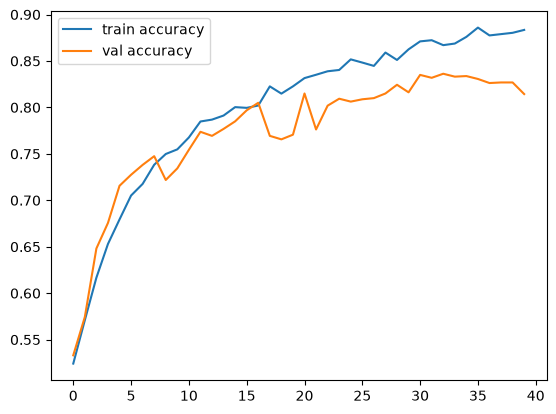

In [9]:
plt.plot(history.history['accuracy'], label='train accuracy')
plt.plot(history.history['val_accuracy'], label='val accuracy')
plt.legend()
plt.show()

### Confusion matrix

In [10]:
y_true = np.concatenate([y for x, y in test], axis = 0)
y_pred = (model.predict(test) >0.5).astype(int).flatten()

print(confusion_matrix(y_true, y_pred))
print(classification_report(y_true, y_pred))

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step
[[838 162]
 [155 845]]
              precision    recall  f1-score   support

           0       0.84      0.84      0.84      1000
           1       0.84      0.84      0.84      1000

    accuracy                           0.84      2000
   macro avg       0.84      0.84      0.84      2000
weighted avg       0.84      0.84      0.84      2000



/home/harsh/Work/.venv-tf/bin/python
